Step 1 – Import & Load Data


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import skfuzzy as fuzz
from skfuzzy import control as ctrl


In [19]:
file_path = r"..\data\processed\healthcare_processed.csv"
fuzzy_data = pd.read_csv(file_path)
fuzzy_data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,stroke_risk
0,9046,0,0.816895,0,1,1,3,1,0.801265,0.301260,1,1,1
1,51676,1,0.743652,0,0,1,4,0,0.679023,0.203895,0,1,1
2,31112,0,0.975586,0,1,1,3,0,0.234512,0.254296,0,1,2
3,60182,1,0.597168,0,0,1,3,1,0.536008,0.276060,2,1,2
4,1665,1,0.963379,1,0,1,4,0,0.549349,0.156930,0,1,2


In [20]:
fuzzy_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   int64  
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   int64  
 6   work_type          5110 non-null   int64  
 7   Residence_type     5110 non-null   int64  
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   int64  
 11  stroke             5110 non-null   int64  
 12  stroke_risk        5110 non-null   int64  
dtypes: float64(3), int64(10)
memory usage: 519.1 KB


In [21]:
fuzzy_data.describe().T

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.0,17741.250000,36932.000000,54682.000000,72940.0
gender,5110.0,0.586301,0.492941,0.0,0.000000,1.000000,1.000000,2.0
age,5110.0,0.526692,0.276033,0.0,0.304199,0.548340,0.743652,1.0
hypertension,5110.0,0.097456,0.296607,0.0,0.000000,0.000000,0.000000,1.0
heart_disease,5110.0,0.054012,0.226063,0.0,0.000000,0.000000,0.000000,1.0
ever_married,5110.0,0.656164,0.475034,0.0,0.000000,1.000000,1.000000,1.0
work_type,5110.0,2.495499,1.278532,0.0,1.000000,3.000000,3.000000,4.0
Residence_type,5110.0,0.508023,0.499985,0.0,0.000000,1.000000,1.000000,1.0
avg_glucose_level,5110.0,0.235563,0.209046,0.0,0.102137,0.169721,0.272228,1.0
bmi,5110.0,0.212624,0.088197,0.0,0.154639,0.203895,0.257732,1.0


In [22]:
fuzzy_data.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke', 'stroke_risk'],
      dtype='object')

In [36]:
# Select features for Fuzzy system
X_fuzzy = fuzzy_data[['age', 'bmi','gender','ever_married','work_type',
                      'smoking_status', 'avg_glucose_level', 'hypertension',
                      'heart_disease', 'Residence_type']]
y_fuzzy = fuzzy_data['stroke_risk']  # 0=Low, 1=Medium, 2=High

X_fuzzy.head()



,age,bmi,gender,ever_married,work_type,smoking_status,avg_glucose_level,hypertension,heart_disease,Residence_type
0,0.816895,0.301260,0,1,3,1,0.801265,0,1,1
1,0.743652,0.203895,1,1,4,0,0.679023,0,0,0
2,0.975586,0.254296,0,1,3,0,0.234512,0,1,0
3,0.597168,0.276060,1,1,3,2,0.536008,0,0,1
4,0.963379,0.156930,1,1,4,0,0.549349,1,0,0


Step 2 – Define Fuzzy Variables

In [38]:
# Step 2: Define Fuzzy Variables

# Input variables
age = ctrl.Antecedent(np.arange(0, 101, 1), 'age')  # 0-100 years
bmi = ctrl.Antecedent(np.arange(10, 60, 1), 'bmi')  # Body Mass Index
avg_glucose_level = ctrl.Antecedent(np.arange(50, 300, 1), 'avg_glucose_level')  # blood sugar

hypertension = ctrl.Antecedent(np.arange(0, 2, 1), 'hypertension')  # 0 or 1
heart_disease = ctrl.Antecedent(np.arange(0, 2, 1), 'heart_disease')  # 0 or 1

smoking_status = ctrl.Antecedent(np.arange(0, 3, 1), 'smoking_status')  # 0=never, 1=formerly, 2=smokes

# Output variable
stroke_risk = ctrl.Consequent(np.arange(0, 3, 1), 'stroke_risk')  # 0=Low, 1=Medium, 2=High


In [25]:
# Age
age = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'age')
age['young'] = fuzz.trimf(age.universe, [0, 0, 0.35])
age['middle'] = fuzz.trimf(age.universe, [0.3, 0.5, 0.7])
age['old'] = fuzz.trimf(age.universe, [0.65, 1, 1])

# BMI
bmi = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'bmi')
bmi['low'] = fuzz.trimf(bmi.universe, [0, 0, 0.45])
bmi['medium'] = fuzz.trimf(bmi.universe, [0.4, 0.55, 0.7])
bmi['high'] = fuzz.trimf(bmi.universe, [0.65, 1, 1])

# Average Glucose Level
avg_glucose = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'avg_glucose_level')
avg_glucose['low'] = fuzz.trimf(avg_glucose.universe, [0, 0, 0.35])
avg_glucose['medium'] = fuzz.trimf(avg_glucose.universe, [0.3, 0.55, 0.75])
avg_glucose['high'] = fuzz.trimf(avg_glucose.universe, [0.7, 1, 1])

In [26]:
stroke_risk = ctrl.Consequent(np.arange(0, 3, 1), 'stroke_risk')
stroke_risk['low'] = fuzz.trimf(stroke_risk.universe, [0, 0, 1])
stroke_risk['medium'] = fuzz.trimf(stroke_risk.universe, [0, 1, 2])
stroke_risk['high'] = fuzz.trimf(stroke_risk.universe, [1, 2, 2])

c:\Users\hp\anaconda3\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


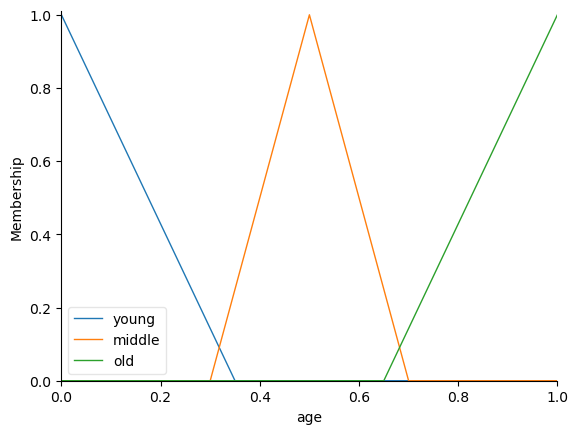

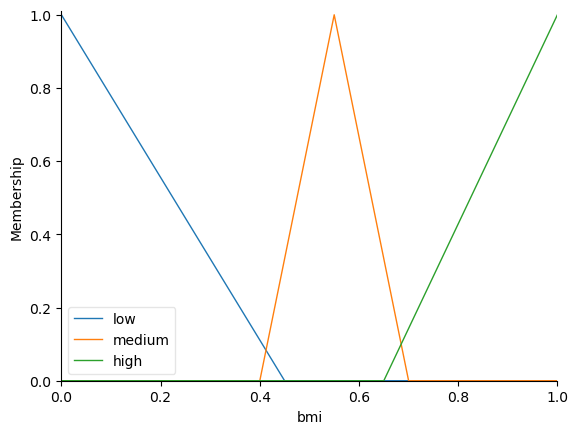

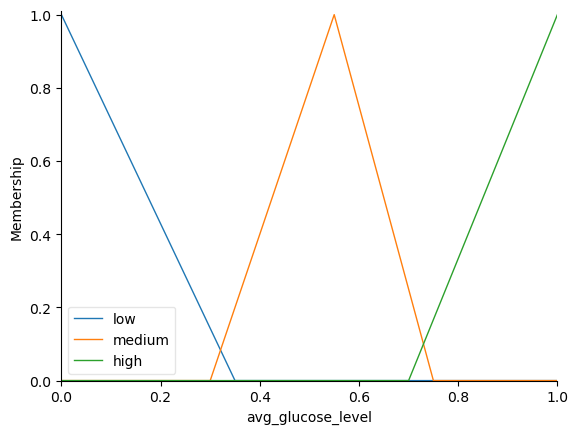

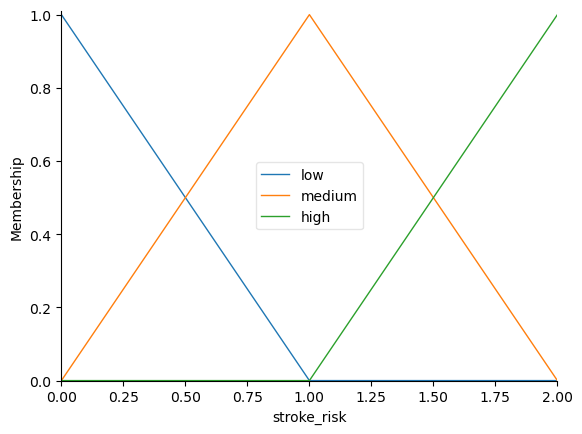

In [27]:
age.view()
bmi.view()
avg_glucose.view()
stroke_risk.view()
plt.show()

In [28]:
# Hypertension
hypertension = ctrl.Antecedent(np.arange(0, 2, 1), 'hypertension')  # 0 or 1
hypertension['no'] = fuzz.trimf(hypertension.universe, [0, 0, 0.5])
hypertension['yes'] = fuzz.trimf(hypertension.universe, [0.5, 1, 1])

# Heart Disease
heart_disease = ctrl.Antecedent(np.arange(0, 2, 1), 'heart_disease')  # 0 or 1
heart_disease['no'] = fuzz.trimf(heart_disease.universe, [0, 0, 0.5])
heart_disease['yes'] = fuzz.trimf(heart_disease.universe, [0.5, 1, 1])


In [29]:
gender = ctrl.Antecedent(np.arange(0, 3, 1), 'gender')
gender['male'] = fuzz.trimf(gender.universe, [-0.5, 0, 0.5])
gender['female'] = fuzz.trimf(gender.universe, [0, 1, 2])
gender['other'] = fuzz.trimf(gender.universe, [1.5, 2, 2.5])


In [30]:
ever_married = ctrl.Antecedent(np.arange(0, 2, 1), 'ever_married')
ever_married['no'] = fuzz.trimf(ever_married.universe, [0, 0, 0.5])
ever_married['yes'] = fuzz.trimf(ever_married.universe, [0.5, 1, 1])


In [31]:
work_type = ctrl.Antecedent(np.arange(0, 5, 1), 'work_type')
work_type['children'] = fuzz.trimf(work_type.universe, [-0.5, 0, 0.5])
work_type['govt_job'] = fuzz.trimf(work_type.universe, [0.5, 1, 1.5])
work_type['never_worked'] = fuzz.trimf(work_type.universe, [1.5, 2, 2.5])
work_type['private'] = fuzz.trimf(work_type.universe, [2.5, 3, 3.5])
work_type['self_employed'] = fuzz.trimf(work_type.universe, [3.5, 4, 4.5])


In [32]:
smoking_status = ctrl.Antecedent(np.arange(0, 4, 1), 'smoking_status')
smoking_status['never'] = fuzz.trimf(smoking_status.universe, [-0.5, 0, 0.5])
smoking_status['formerly'] = fuzz.trimf(smoking_status.universe, [0.5, 1, 1.5])
smoking_status['smokes'] = fuzz.trimf(smoking_status.universe, [1.5, 2, 2.5])
smoking_status['unknown'] = fuzz.trimf(smoking_status.universe, [2.5, 3, 3.5])


In [33]:
Residence_type = ctrl.Antecedent(np.arange(0, 2, 1), 'Residence_type')
Residence_type['rural'] = fuzz.trimf(Residence_type.universe, [0, 0, 0.5])
Residence_type['urban'] = fuzz.trimf(Residence_type.universe, [0.5, 1, 1])


In [34]:
from skfuzzy.control import Rule
# Fuzzy Rules — Expert-Level Set

rule1  = ctrl.Rule(age['young'] & bmi['normal'] & hypertension['no'] & heart_disease['no'], stroke_risk['low'])
rule2  = ctrl.Rule(age['young'] & bmi['high'] & hypertension['yes'], stroke_risk['medium'])
rule3  = ctrl.Rule(age['middle'] & bmi['high'] & hypertension['yes'] & heart_disease['yes'], stroke_risk['high'])
rule4  = ctrl.Rule(age['old'] & hypertension['yes'], stroke_risk['high'])
rule5  = ctrl.Rule(age['old'] & heart_disease['yes'], stroke_risk['high'])

rule6  = ctrl.Rule(avg_glucose['high'] & hypertension['yes'], stroke_risk['high'])
rule7  = ctrl.Rule(avg_glucose['medium'] & bmi['high'], stroke_risk['medium'])
rule8  = ctrl.Rule(avg_glucose['low'] & bmi['low'], stroke_risk['low'])

rule9  = ctrl.Rule(smoking_status['smokes'] & hypertension['yes'], stroke_risk['high'])
rule10 = ctrl.Rule(smoking_status['smokes'] & age['middle'], stroke_risk['medium'])
rule11 = ctrl.Rule(smoking_status['never'] & age['young'], stroke_risk['low'])

rule12 = ctrl.Rule(work_type['private'] & bmi['high'], stroke_risk['medium'])
rule13 = ctrl.Rule(work_type['self-employed'] & hypertension['yes'], stroke_risk['high'])
rule14 = ctrl.Rule(work_type['govt_job'] & bmi['normal'], stroke_risk['low'])

rule15 = ctrl.Rule(ever_married['yes'] & age['old'], stroke_risk['medium'])
rule16 = ctrl.Rule(ever_married['no'] & age['young'], stroke_risk['low'])

rule17 = ctrl.Rule(Residence_type['urban'] & avg_glucose['high'], stroke_risk['medium'])
rule18 = ctrl.Rule(Residence_type['rural'] & hypertension['yes'], stroke_risk['medium'])

rule19 = ctrl.Rule(bmi['low'] & age['old'], stroke_risk['medium'])
rule20 = ctrl.Rule(bmi['high'] & age['old'] & heart_disease['yes'], stroke_risk['high'])

# ------------------------------
# Create the control system
# ------------------------------
stroke_ctrl = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9, rule10,
    rule11, rule12, rule13, rule14, rule15, rule16, rule17, rule18, rule19, rule20
])
stroke_simulator = ctrl.ControlSystemSimulation(stroke_ctrl)


ValueError: Membership function 'normal' does not exist for Antecedent bmi.
Available options: 'low'; 'medium', or 'high'.

In [ ]:
# Example: first row
row = X_fuzzy.iloc[0]

stroke_simulator.input['age'] = row['age']
stroke_simulator.input['bmi'] = row['bmi']
stroke_simulator.input['avg_glucose_level'] = row['avg_glucose_level']
stroke_simulator.input['hypertension'] = row['hypertension']
stroke_simulator.input['heart_disease'] = row['heart_disease']
stroke_simulator.input['gender'] = row['gender']
stroke_simulator.input['ever_married'] = row['ever_married']
stroke_simulator.input['work_type'] = row['work_type']
stroke_simulator.input['smoking_status'] = row['smoking_status']
stroke_simulator.input['Residence_type'] = row['Residence_type']

# Compute Fuzzy output
stroke_simulator.compute()

# Output
predicted_value = stroke_simulator.output['stroke_risk']

# Map numeric to label
if predicted_value < 0.5:
    predicted_label = 'Low'
elif predicted_value < 1.5:
    predicted_label = 'Medium'
else:
    predicted_label = 'High'

print(predicted_value, predicted_label)


1.222222222222222 Medium


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix

# Assuming X_fuzzy and y_fuzzy are already defined
predictions = []

for idx, row in X_fuzzy.iterrows():
    # Assign inputs
    stroke_simulator.input['age'] = row['age']
    stroke_simulator.input['bmi'] = row['bmi']
    stroke_simulator.input['avg_glucose_level'] = row['avg_glucose_level']
    stroke_simulator.input['hypertension'] = row['hypertension']
    stroke_simulator.input['heart_disease'] = row['heart_disease']
    stroke_simulator.input['gender'] = row['gender']
    stroke_simulator.input['ever_married'] = row['ever_married']
    stroke_simulator.input['work_type'] = row['work_type']
    stroke_simulator.input['smoking_status'] = row['smoking_status']
    stroke_simulator.input['Residence_type'] = row['Residence_type']
    
    # Compute output
    stroke_simulator.compute()
    val = stroke_simulator.output['stroke_risk']
    
    # Map numeric output to label
    if val < 0.5:
        label = 'Low'
    elif val < 1.5:
        label = 'Medium'
    else:
        label = 'High'
        
    predictions.append(label)

# Add predictions to dataframe
fuzzy_results = X_fuzzy.copy()
fuzzy_results['stroke_risk_pred'] = predictions
fuzzy_results['stroke_risk_true'] = y_fuzzy.map({0:'Low',1:'Medium',2:'High'})

# Evaluate
accuracy = accuracy_score(fuzzy_results['stroke_risk_true'], fuzzy_results['stroke_risk_pred'])
conf_matrix = confusion_matrix(fuzzy_results['stroke_risk_true'], fuzzy_results['stroke_risk_pred'],
                               labels=['Low','Medium','High'])

print(f"Fuzzy Baseline Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)


Fuzzy Baseline Accuracy: 0.3294
Confusion Matrix:
[[   0 2775    0]
 [   0 1683    0]
 [   0  652    0]]


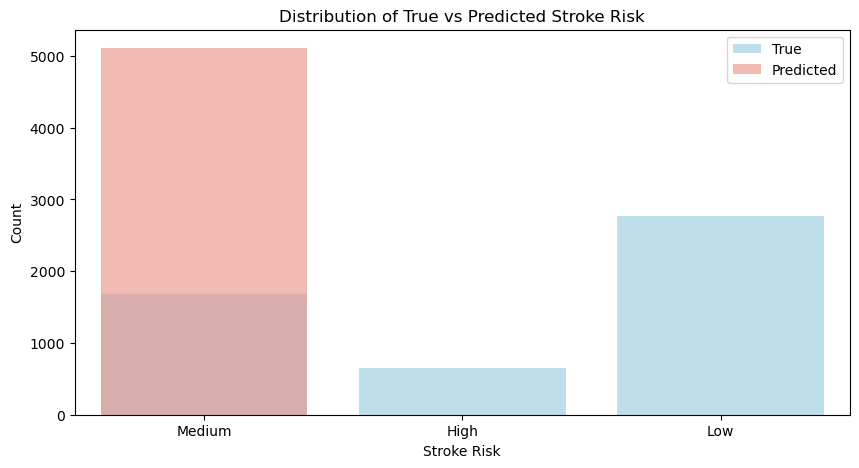

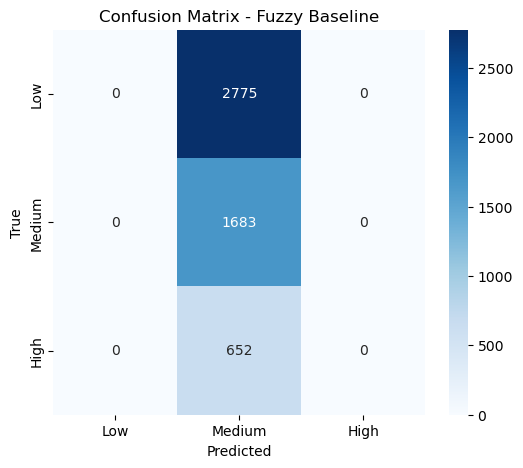

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------
# 1️⃣ Distribution of predicted vs true labels
# ------------------------------
plt.figure(figsize=(10,5))

# Count of true labels
sns.countplot(x='stroke_risk_true', data=fuzzy_results, color='skyblue', label='True', alpha=0.6)

# Count of predicted labels (overlay)
sns.countplot(x='stroke_risk_pred', data=fuzzy_results, color='salmon', label='Predicted', alpha=0.6)

plt.title('Distribution of True vs Predicted Stroke Risk')
plt.xlabel('Stroke Risk')
plt.ylabel('Count')
plt.legend()
plt.show()

# ------------------------------
# 2️⃣ Confusion Matrix Heatmap
# ------------------------------
labels = ['Low','Medium','High']
conf_matrix = confusion_matrix(fuzzy_results['stroke_risk_true'], fuzzy_results['stroke_risk_pred'], labels=labels)

plt.figure(figsize=(6,5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Fuzzy Baseline')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
